# Notebook 13 – Model Error Analysis



In [1]:
import time
import numpy as np
import torch
from torch import nn
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)

PyTorch: 2.14.0+cpu | device: cpu


## Error analysis method and table
Collect held-out predictions and confidence; review a stratified sample; label error categories with a written rubric; count errors by class/condition; then test one intervention.

| Error Type | Example | Possible Cause | Impact | Proposed Improvement |
|---|---|---|---|---|
| Similar classes | overlapping shapes | insufficient discriminative features | subgroup error rate | inspect targeted examples/data |
| Image quality | blur/noise | acquisition or resize artifact | measure error rate | improve capture/robust augmentation |
| Size/orientation | tiny or rotated subject | preprocessing mismatch | compare condition bins | task-valid crop/rotation augmentation |
| Background/occlusion | clutter/hidden object | shortcut or missing context | subgroup count | varied data or crop if justified |

Do not assign a cause from one vivid example.

errors: 6 of 450
most confused count,true,pred: [(np.int64(2), 9, 8), (np.int64(1), 8, 9), (np.int64(1), 8, 1), (np.int64(1), 5, 9), (np.int64(1), 4, 7)]


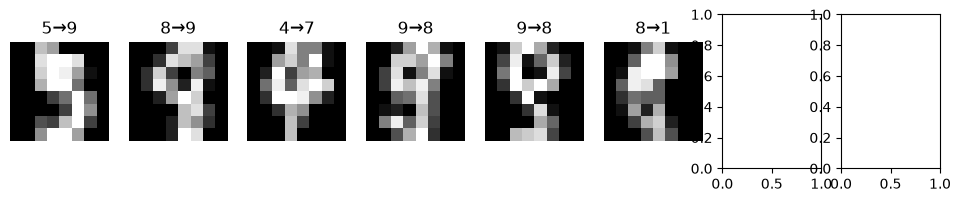

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
d=load_digits(); indices=np.arange(len(d.target)); tr,te=train_test_split(indices,test_size=.25,random_state=8,stratify=d.target)
clf=RandomForestClassifier(n_estimators=150,random_state=8).fit(d.data[tr],d.target[tr]); pred=clf.predict(d.data[te]); truth=d.target[te]; wrong=np.flatnonzero(pred!=truth)
print('errors:',len(wrong),'of',len(te)); cm=confusion_matrix(truth,pred)
pairs=[(cm[i,j],i,j) for i in range(10) for j in range(10) if i!=j and cm[i,j]]; print('most confused count,true,pred:',sorted(pairs,reverse=True)[:8])
fig,axes=plt.subplots(1,8,figsize=(12,2))
for ax,k in zip(axes,wrong[:8]): ax.imshow(d.images[te[k]],cmap='gray'); ax.set_title(f'{truth[k]}→{pred[k]}'); ax.axis('off')
plt.show()

## Interpret and propose improvements
For each frequent error type, include representative examples, counts/impact, a plausible cause, and a testable improvement. If metadata such as orientation or background is unavailable, first derive or collect it; do not claim subgroup causation without subgroup evidence. Check improvement on validation data before touching test results.